# Trabajo Práctico 3 (TP3): Clasificación de Imágenes de Cáncer de Mama usando PCA y SVD

## Objetivo
El objetivo de este Trabajo Práctico es aplicar los conceptos de reducción de dimensionalidad vistos en la Clase 8 (**SVD y PCA**) para construir un clasificador de imágenes médicas. 

Trabajaremos con imágenes de ultrasonido de mama para clasificarlas en **Benignas** o **Malignas**.

## 1. Obtención del Dataset (BreastMNIST)
Para este TP utilizaremos **BreastMNIST**, un subconjunto del famoso dataset MedMNIST, el cual contiene imágenes de ultrasonido de mama de 28x28 píxeles en escala de grises.

**Instrucciones:** Si no tienes instalada la librería `medmnist`, ejecuta la siguiente celda.

In [1]:
!pip install medmnist

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import medmnist
from medmnist import BreastMNIST

# Descargar y cargar los datos
train_dataset = BreastMNIST(split='train', download=True)
test_dataset = BreastMNIST(split='test', download=True)

# Extraer las imágenes y las etiquetas
X_train = train_dataset.imgs
y_train = train_dataset.labels.squeeze()

X_test = test_dataset.imgs
y_test = test_dataset.labels.squeeze()

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (546, 28, 28)
Dimensiones de X_test: (156, 28, 28)


### Consigna 1: Visualización Exploratoria
Extrae y visualiza al menos 3 imágenes correspondientes a tumores benignos (etiqueta 0) y 3 imágenes a tumores malignos (etiqueta 1).
¿Notas alguna diferencia visual obvia entre ambas clases?

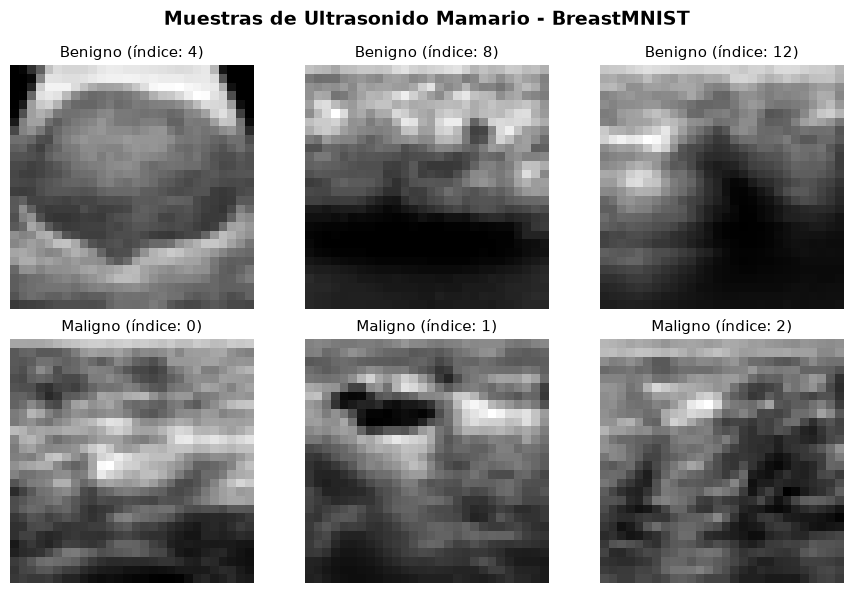

In [2]:
# TODO: Escribe tu código de visualización aquí
# 1. Obtener los índices de las primeras 3 muestras de cada clase
idx_benign = np.where(y_train == 0)[0][:3]
idx_malignant = np.where(y_train == 1)[0][:3]

# 2. Configurar la grilla de visualización (2 filas x 3 columnas)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))

# Fila 1: Tumores Benignos (etiqueta 0)
for i, idx in enumerate(idx_benign):
    axes[0, i].imshow(X_train[idx], cmap='gray')
    axes[0, i].set_title(f"Benigno (índice: {idx})", fontsize=11)
    axes[0, i].axis('off')

# Fila 2: Tumores Malignos (etiqueta 1)
for i, idx in enumerate(idx_malignant):
    axes[1, i].imshow(X_train[idx], cmap='gray')
    axes[1, i].set_title(f"Maligno (índice: {idx})", fontsize=11)
    axes[1, i].axis('off')

plt.suptitle("Muestras de Ultrasonido Mamario - BreastMNIST", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
#A simple vista es difícil notar alguna diferencia debido a la baja
# resolucion de las imágenes, pero se llega a identificar algunas "manchas" negras

## 2. Preprocesamiento y Vectorización
Para aplicar PCA o SVD estándar, necesitamos que cada imagen (una matriz 2D de 28x28) se convierta en un vector 1D (784 píxeles).

### Consigna 2: Vectorización y Centrado
1. Transforma `X_train` y `X_test` de dimensiones `(N, 28, 28)` a `(N, 784)`.
2. Calcula el **rostro (imagen) medio** del conjunto de entrenamiento y réstalo a todas las imágenes (tanto de train como de test) para centrar los datos.

Dimensiones X_train vectorizado: (546, 784)
Dimensiones X_test vectorizado:  (156, 784)
Media global de X_train_centered (debe ser cercana a 0): 6.80e-17


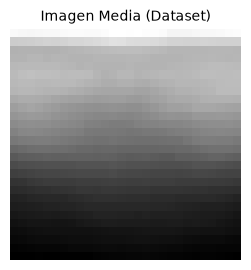

In [3]:
# TODO: Escribe tu código de preprocesamiento y centrado aquí
# 1. Convertir a tipo flotante para evitar problemas de desbordamiento (overflow) con uint8
# y aplanar las matrices de (N, 28, 28) a (N, 784)
X_train_flat = X_train.reshape(X_train.shape[0], -1).astype(np.float64)
X_test_flat = X_test.reshape(X_test.shape[0], -1).astype(np.float64)

# 2. Calcular la imagen media (mean image) sobre el conjunto de entrenamiento
mean_image = np.mean(X_train_flat, axis=0)

# 3. Restar la media a los conjuntos de entrenamiento y prueba (centrado de datos)
X_train_centered = X_train_flat - mean_image
X_test_centered = X_test_flat - mean_image

print(f"Dimensiones X_train vectorizado: {X_train_flat.shape}")
print(f"Dimensiones X_test vectorizado:  {X_test_flat.shape}")
print(f"Media global de X_train_centered (debe ser cercana a 0): {np.mean(X_train_centered):.2e}")

# Visualización opcional de la "imagen media"
plt.figure(figsize=(3, 3))
plt.imshow(mean_image.reshape(28, 28), cmap='gray')
plt.title("Imagen Media (Dataset)", fontsize=10)
plt.axis('off')
plt.show()


## 3. Reducción de Dimensionalidad con SVD / PCA
Ahora aplicaremos SVD a nuestra matriz de datos centrados para extraer los **Componentes Principales** (las "Eigen-imágenes").

### Consigna 3: Cálculo de SVD
1. Aplica SVD a la matriz de entrenamiento centrada para obtener `U`, `S` y `V^T`.
2. Grafica la varianza explicada acumulada y decide un valor de `r` (número de componentes) que conserve al menos el 90% de la energía/varianza.
3. Visualiza los primeros 5 componentes principales (Eigen-imágenes) redimensionándolos de nuevo a 28x28.

Número de componentes r para conservar al menos el 90% de varianza: 36
Varianza explicada con r=36: 90.11%


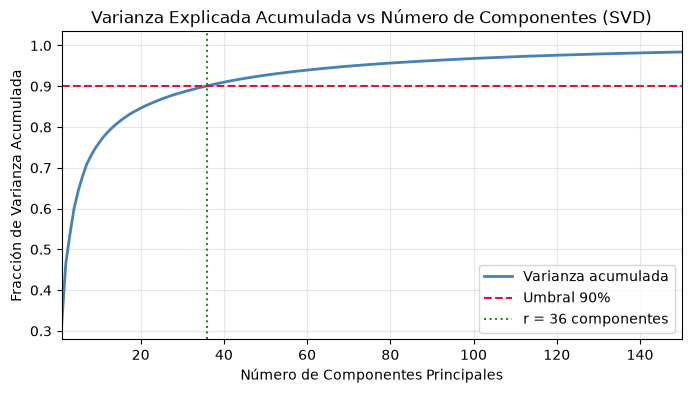

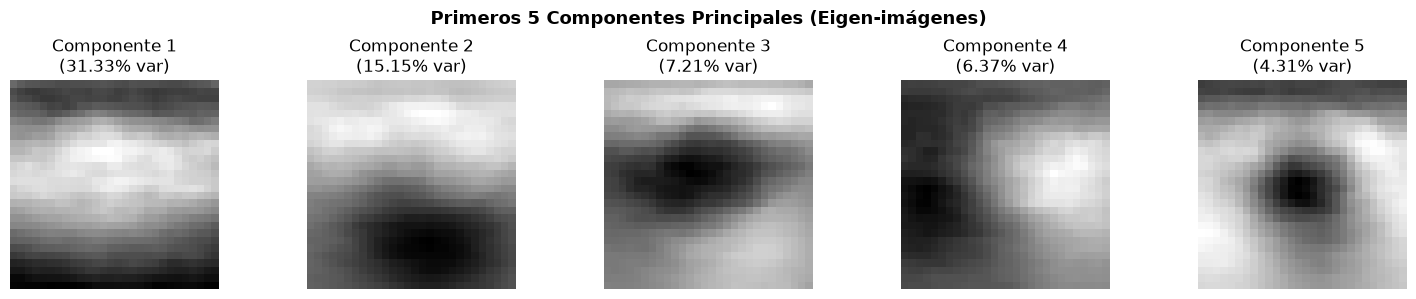

In [4]:
# TODO: Escribe tu código de SVD y visualización aquí
# 1. Aplicar Descomposición en Valores Singulares (SVD) a la matriz centrada
# full_matrices=False calcula la descomposición reducida (SVD compacta/económica)
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)

# 2. Calcular la energía / varianza explicada acumulada
# La energía asociada a cada valor singular es proporcional a S^2
variance_explained = (S ** 2) / np.sum(S ** 2)
cumulative_variance = np.cumsum(variance_explained)

# Determinar el número r de componentes para alcanzar al menos el 90% de varianza
target_var = 0.90
r = np.argmax(cumulative_variance >= target_var) + 1

print(f"Número de componentes r para conservar al menos el {target_var*100:.0f}% de varianza: {r}")
print(f"Varianza explicada con r={r}: {cumulative_variance[r-1] * 100:.2f}%")

# Gráfico de Varianza Explicada Acumulada
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, color='steelblue', lw=2, label='Varianza acumulada')
plt.axhline(y=target_var, color='crimson', linestyle='--', label=f'Umbral {int(target_var*100)}%')
plt.axvline(x=r, color='forestgreen', linestyle=':', label=f'r = {r} componentes')
plt.title("Varianza Explicada Acumulada vs Número de Componentes (SVD)", fontsize=12)
plt.xlabel("Número de Componentes Principales")
plt.ylabel("Fracción de Varianza Acumulada")
plt.xlim(1, 150)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Visualizar los primeros 5 componentes principales (Eigen-imágenes)
# Las filas de Vt corresponden a las direcciones principales en el espacio de píxeles
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    eigen_image = Vt[i].reshape(28, 28)
    axes[i].imshow(eigen_image, cmap='gray')
    axes[i].set_title(f"Componente {i + 1}\n({variance_explained[i]*100:.2f}% var)")
    axes[i].axis('off')

plt.suptitle("Primeros 5 Componentes Principales (Eigen-imágenes)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Proyección y Clasificación
Una vez que tenemos la matriz de proyección (los primeros `r` componentes de `V^T` o equivalentemente usando Scikit-Learn `PCA`), proyectaremos los datos a un espacio de menor dimensión.

### Consigna 4: Clasificador Predictivo
1. Proyecta `X_train_centrado` y `X_test_centrado` sobre los primeros `r` componentes principales.
2. Entrena un clasificador simple, como **Regresión Logística** o **k-Nearest Neighbors (k-NN)**, usando las proyecciones de entrenamiento.
3. Evalúa el modelo en el conjunto de prueba usando `accuracy_score` y `classification_report`.
4. Prueba variar el número de componentes `r` (ej: 5, 20, 50) y describe cómo afecta el rendimiento.

Dimensiones reducidas de X_train: (546, 36)
Dimensiones reducidas de X_test:  (156, 36)

================ Rendimiento con r = 36 ================
Accuracy en Test: 0.7949 (79.49%)

Reporte de Clasificación:
              precision    recall  f1-score   support

 Benigno (0)       0.71      0.40      0.52        42
 Maligno (1)       0.81      0.94      0.87       114

    accuracy                           0.79       156
   macro avg       0.76      0.67      0.69       156
weighted avg       0.78      0.79      0.77       156

Comparación de Accuracy variando r:
---------------------------------------------
r      | Regresión Logística  | k-NN (k=5)     
---------------------------------------------
5      | 0.8013               | 0.7500         
10     | 0.7885               | 0.7564         
20     | 0.8013               | 0.7821         
36     | 0.7949               | 0.7756         
50     | 0.7949               | 0.7821         
100    | 0.7564               | 0.7756         
--

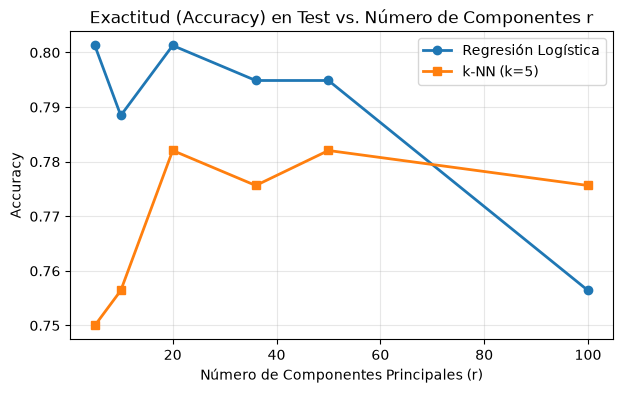

In [5]:
# TODO: Escribe tu código de clasificación aquí
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Proyectar los datos sobre los primeros 'r' componentes (r obtenido en Consigna 3)
# La matriz de proyección es la transpuesta de las primeras r filas de Vt
V_r = Vt[:r, :].T  # Dimensión: (784, r)

X_train_proj = X_train_centered @ V_r
X_test_proj = X_test_centered @ V_r

print(f"Dimensiones reducidas de X_train: {X_train_proj.shape}")
print(f"Dimensiones reducidas de X_test:  {X_test_proj.shape}")

# 2. Entrenar y evaluar el clasificador principal con el r óptimo (Regresión Logística)
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_proj, y_train)

y_pred = clf.predict(X_test_proj)
acc = accuracy_score(y_test, y_pred)

print(f"\n================ Rendimiento con r = {r} ================")
print(f"Accuracy en Test: {acc:.4f} ({acc*100:.2f}%)\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Benigno (0)', 'Maligno (1)']))

# 3. Variar el número de componentes r (ej: 5, 20, 36, 50, 100) y evaluar impacto
r_candidates = [5, 10, 20, r, 50, 100]
accuracies_lr = []
accuracies_knn = []

for r_val in r_candidates:
    V_sub = Vt[:r_val, :].T
    X_tr_p = X_train_centered @ V_sub
    X_te_p = X_test_centered @ V_sub
    
    # Regresión Logística
    model_lr = LogisticRegression(max_iter=1000, random_state=42)
    model_lr.fit(X_tr_p, y_train)
    accuracies_lr.append(accuracy_score(y_test, model_lr.predict(X_te_p)))
    
    # k-NN
    model_knn = KNeighborsClassifier(n_neighbors=5)
    model_knn.fit(X_tr_p, y_train)
    accuracies_knn.append(accuracy_score(y_test, model_knn.predict(X_te_p)))

# Mostrar tabla comparativa
print("Comparación de Accuracy variando r:")
print("-" * 45)
print(f"{'r':<6} | {'Regresión Logística':<20} | {'k-NN (k=5)':<15}")
print("-" * 45)
for r_val, acc_l, acc_k in zip(r_candidates, accuracies_lr, accuracies_knn):
    print(f"{r_val:<6} | {acc_l:<20.4f} | {acc_k:<15.4f}")
print("-" * 45)

# Gráfico del impacto de r
plt.figure(figsize=(7, 4))
plt.plot(r_candidates, accuracies_lr, marker='o', label='Regresión Logística', lw=2)
plt.plot(r_candidates, accuracies_knn, marker='s', label='k-NN (k=5)', lw=2)
plt.title("Exactitud (Accuracy) en Test vs. Número de Componentes r")
plt.xlabel("Número de Componentes Principales (r)")
plt.ylabel("Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [ ]:
#Si usamos el algoritmo k-NN podemos observar...
#Valores bajos de componentes logran un rendimiento bastante alto e interesante
#Con solamente 5 componentes ya se obtiene una precisión del 75% aproximadamente.

#Si usamos Regresión Logística
#Se puede ver que al aumentar el tamaño de las dimensiones, la precisión va en decaída
#ya que podemos introducir componentes innecesarias como ruido y demás.

#En ambos casos podemos observar que con 20 componentes tenemos la mayor precisión.

### Consigna Opcional (Bonus)
Implementa un clasificador que, en lugar de usar un modelo externo como Regresión Logística, utilice directamente la reconstrucción de PCA. Por ejemplo, midiendo el error de reconstrucción de una imagen de prueba usando los componentes calculados únicamente sobre imágenes benignas vs imágenes malignas.